# Research Paper Ingestion & Processing

In [1]:
%pip install arxiv langchain langchain_community pypdf pandas matplotlib scikit-learn seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import arxiv
from langchain_community.document_loaders import PyPDFLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
import tempfile
import time
import json
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from langchain_community.document_loaders import PyPDFLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
from collections import Counter
from itertools import islice
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE

## Text cleaning

In [3]:
def clean_text(text):
    """
    Cleans extracted research paper text:
    - Removes citations
    - Removes 'References' section
    - Cleans page numbers and headers
    - Removes LaTeX equations
    """
    text = re.sub(r"\[\d+\]", "", text)  # Remove citations like [15]
    text = re.sub(r"\(.*?\d{4}.*?\)", "", text)  # Remove inline citations
    text = re.sub(r"\bReferences\b.*", "", text, flags=re.DOTALL)  # Remove references section
    text = re.sub(r"Page\s\d+\sof\s\d+", "", text)  # Remove page numbers
    text = re.sub(r"\$.*?\$", "", text)  # Remove LaTeX math expressions
    text = re.sub(r"\s+", " ", text)  # Normalize spaces
    return text.strip()

## Fetching Research Papers from ArXiv
- Query ArXiv for academic papers based on a search term.
- Instead of storing PDFs, we load them **temporarily** then extract the text.

In [4]:
def fetch_papers(query="LLM", max_results=5):
    """
    Fetches academic papers from ArXiv based on a search term, processes the PDFs,
    extracts text, and splits the content into smaller, structured chunks.

    Parameters:
        query (str): The search term to query ArXiv for research papers.
        max_results (int): The maximum number of papers to retrieve.

    Returns:
        all_chunks: A list of document chunks extracted from the fetched papers.
    """
    
    # Initialize an ArXiv client
    client = arxiv.Client()

    # Search query with sorting (descending order to get the latest papers)
    search = arxiv.Search(query=query, max_results=max_results, sort_order=arxiv.SortOrder.Descending)
    
    all_chunks = []  # List to store extracted text chunks
    
    for result in client.results(search):
        # Display the title of the paper currently being processed
        print(f"Processing: {result.title}")
        
        # Create a temporary file to store the downloaded PDF
        temp_pdf = tempfile.NamedTemporaryFile(delete=False, suffix=".pdf")
        try:
                result.download_pdf(filename=temp_pdf.name)
                print(f"-> Downloaded: {result.title}")
                temp_pdf.close()

                # Load PDF file 
                loader = PyPDFLoader(temp_pdf.name)
                papers = loader.load()
                
                # Combine all pages into a single string
                full_text = " ".join(p.page_content for p in papers)
                cleaned_text = clean_text(full_text)

                # Split the extracted text into chunks
                text_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
                paper_chunks = text_splitter.create_documents([cleaned_text])
                
                # Add extracted chunks to the list
                all_chunks.extend(paper_chunks) 
                
        except (FileNotFoundError, ConnectionResetError) as e:
                print("Error occurred while downloading or processing PDF:", e)
                time.sleep(5)
    
    # Print total number of extracted chunks
    print(f"Total chunks extracted: {len(all_chunks)}")

    return all_chunks

## Exploratory Data Analysis

In [ ]:
import re
from collections import Counter
from itertools import islice
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE

# Define EDA functions with inline stopword removal
def analyze_text_chunks(chunks):
    num_chunks = len(chunks)
    chunk_lengths = [len(chunk.page_content.split()) for chunk in chunks]
    df = pd.DataFrame({"Chunk #": range(1, num_chunks+1), "Word Count": chunk_lengths})
    
    print("\nSummary Statistics for Chunk Sizes:")
    print(df.describe())
    
    plt.figure(figsize=(8,5))
    sns.histplot(df["Word Count"], bins=20, kde=True)
    plt.xlabel("Word Count per Chunk")
    plt.ylabel("Frequency")
    plt.title("Distribution of Word Counts in Chunks")
    plt.show()
    
    return df

def analyze_common_words(chunks, top_n=20):
    # Import stopwords and tokenization utilities locally
    from nltk.corpus import stopwords
    from nltk.tokenize import word_tokenize
    import nltk
    # Download necessary NLTK data quietly
    nltk.download('stopwords', quiet=True)
    nltk.download('punkt', quiet=True)
    
    stop_words = set(stopwords.words('english'))
    
    # Concatenate all page content into one text
    all_text = " ".join(chunk.page_content for chunk in chunks)
    # Tokenize the text and filter out stopwords and non-alphabetic tokens
    tokens = word_tokenize(all_text.lower())
    filtered_tokens = [token for token in tokens if token.isalpha() and token not in stop_words]
    
    word_counts = Counter(filtered_tokens)
    df_words = pd.DataFrame(word_counts.most_common(top_n), columns=["Word", "Frequency"])
    
    print("\nTop", top_n, "Most Common Words (excluding stopwords):")
    print(df_words)
    
    plt.figure(figsize=(10,5))
    sns.barplot(x=df_words["Frequency"], y=df_words["Word"])
    plt.xlabel("Frequency")
    plt.ylabel("Words")
    plt.title("Top " + str(top_n) + " Most Common Words (No Stopwords)")
    plt.show()
    
    return df_words

def analyze_ngrams(chunks, n=2, top_n=20):
    # Import stopwords and tokenization utilities locally
    from nltk.corpus import stopwords
    from nltk.tokenize import word_tokenize
    import nltk
    nltk.download('stopwords', quiet=True)
    nltk.download('punkt', quiet=True)
    
    stop_words = set(stopwords.words('english'))
    
    # Concatenate all page content into one text
    all_text = " ".join(chunk.page_content for chunk in chunks)
    # Tokenize and filter tokens: keep only alphabetic tokens not in stopwords
    tokens = word_tokenize(all_text.lower())
    filtered_tokens = [token for token in tokens if token.isalpha() and token not in stop_words]
    
    # Create n-grams using the filtered tokens
    ngrams_gen = zip(*[islice(filtered_tokens, i, None) for i in range(n)])
    ngram_list = [" ".join(ngram) for ngram in ngrams_gen]
    ngram_counts = Counter(ngram_list)
    
    df_ngrams = pd.DataFrame(ngram_counts.most_common(top_n), columns=[f"{n}-Gram", "Frequency"])
    
    print(f"\nTop {top_n} Most Common {n}-Grams (excluding stopwords):")
    print(df_ngrams)
    
    plt.figure(figsize=(10,5))
    sns.barplot(x=df_ngrams["Frequency"], y=df_ngrams[f"{n}-Gram"])
    plt.xlabel("Frequency")
    plt.ylabel(f"{n}-Grams")
    plt.title(f"Top {top_n} Most Common {n}-Grams (No Stopwords)")
    plt.show()
    
    return df_ngrams

def visualize_embeddings(chunks):
    # Use first 500 words per chunk for embedding visualization
    all_text = [" ".join(chunk.page_content.split()[:500]) for chunk in chunks]
    
    # Convert text to embeddings using TF-IDF (with built-in stopword removal)
    vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
    tfidf_matrix = vectorizer.fit_transform(all_text)
    
    # Reduce dimensionality using t-SNE
    tsne = TSNE(n_components=2, perplexity=5, random_state=42)
    tsne_results = tsne.fit_transform(tfidf_matrix.toarray())
    
    # Plot the t-SNE visualization
    plt.figure(figsize=(8,6))
    plt.scatter(tsne_results[:,0], tsne_results[:,1], alpha=0.5)
    plt.xlabel("t-SNE Component 1")
    plt.ylabel("t-SNE Component 2")
    plt.title("t-SNE Visualization of Research Paper Embeddings")
    plt.show()


# Running code
query = "Large Language Models"
paper_chunks = fetch_papers(query=query, max_results=3)
df_chunks = analyze_text_chunks(paper_chunks)
df_words = analyze_common_words(paper_chunks)
analyze_ngrams(paper_chunks, n=2)
visualize_embeddings(paper_chunks)

for i, chunk in enumerate(paper_chunks[:3]):
    print(f"\nChunk {i+1}:\n{chunk.page_content[:300]}...")

## Running the Paper Retrieval Pipeline
Testing the function by retrieving **3 recent papers** related to **Large Language Models**.

Processing: Lost in Translation: Large Language Models in Non-English Content Analysis
-> Downloaded: Lost in Translation: Large Language Models in Non-English Content Analysis
Processing: Cedille: A large autoregressive French language model
-> Downloaded: Cedille: A large autoregressive French language model
Processing: How Good are Commercial Large Language Models on African Languages?
-> Downloaded: How Good are Commercial Large Language Models on African Languages?
Total chunks extracted: 168

Summary Statistics for Chunk Sizes:
          Chunk #  Word Count
count  168.000000  168.000000
mean    84.500000   78.000000
std     48.641546   12.527813
min      1.000000   40.000000
25%     42.750000   71.750000
50%     84.500000   78.000000
75%    126.250000   83.000000
max    168.000000  149.000000


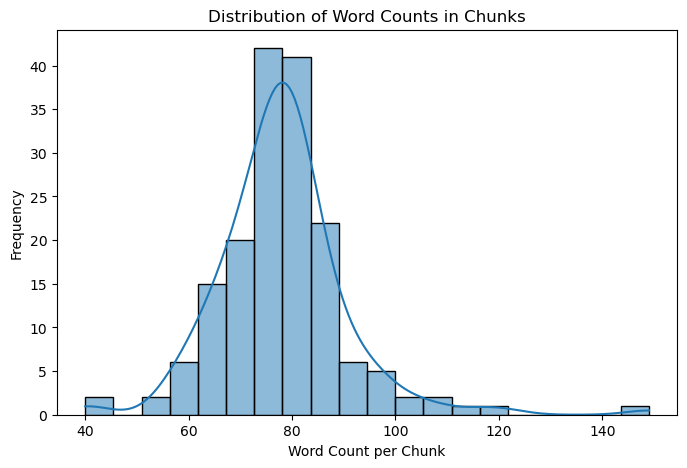


Top 20 Most Common Words (excluding stopwords):
            Word  Frequency
0         models        127
1       language        124
2              w         96
3          https         68
4              e         67
5          model         65
6              n         55
7             et         53
8            url         52
9    translation         49
10     languages         49
11        french         46
12             v         45
13      toxicity         43
14       english         42
15   association         40
16       cedille         38
17          work         37
18          text         37
19  multilingual         36


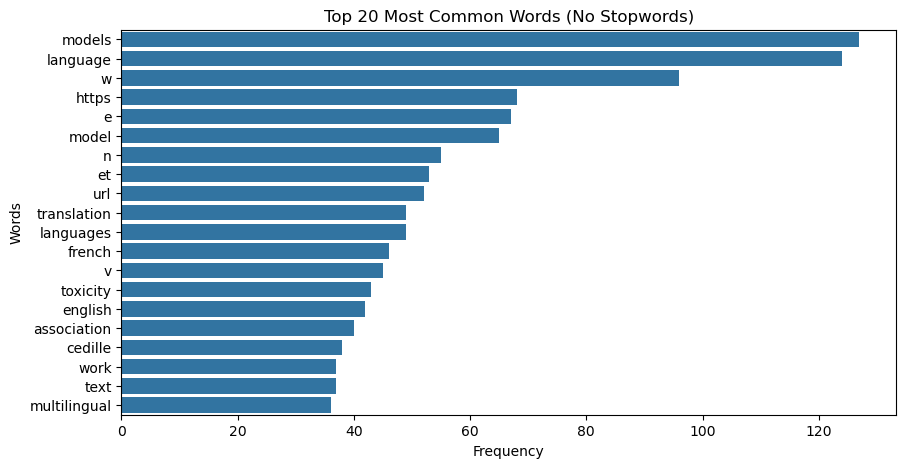


Top 20 Most Common 2-Grams (excluding stopwords):
                       2-Gram  Frequency
0             language models         54
1                   url https         46
2                         w e         34
3         machine translation         23
4   computational linguistics         22
5           african languages         21
6                     doi url         21
7   association computational         20
8                       et al         18
9                       w ang         17
10         africanlp workshop         16
11            nigerian pidgin         15
12            linguistics doi         15
13             large language         14
14             language model         13
15           natural language         13
16         text classiﬁcation         11
17                  pp online         10
18            https africanlp          9
19                       io n          9


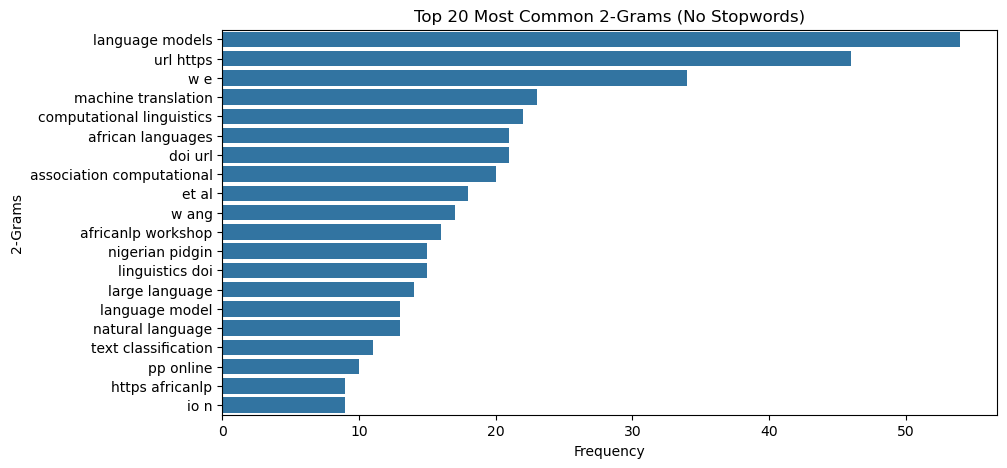

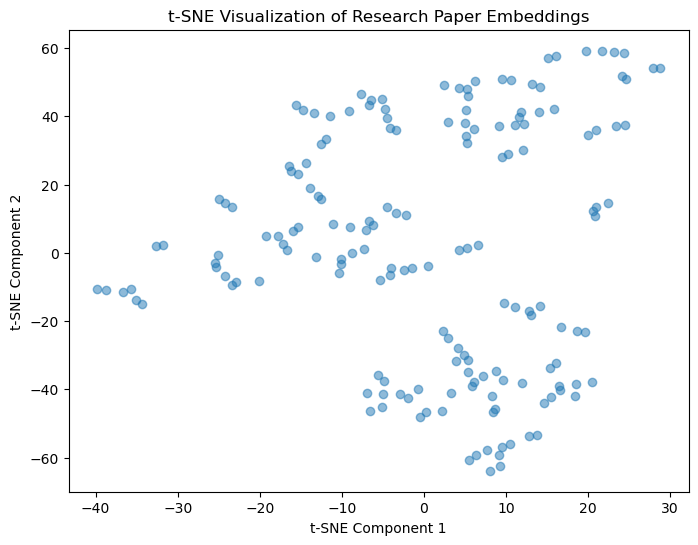


Chunk 1:
Lost in Translation May 2023 A report from Gabriel Nicholas Aliya Bhatia Large Language Models in Non-English Content Analysis GABRIEL NICHOLAS Research Fellow at the Center for Democracy & T echnology. ALIYA BHATIA Policy Analyst, Free Expression Project at the Center for Democracy & T echnology. T...

Chunk 2:
in the digital age. W e shape technology policy, governance, and design with a focus on equity and democratic values. Established in 1996, CDT has been a trusted advocate for digital rights since the earliest days of the internet. The organization is headquartered in W ashington, D.C., and has a Eur...

Chunk 3:
Luria, Nathalie Maréchal, Dhanaraj Thakur, and Caitlin V ogus. ACKNOWLEDGMENTS W e thank Pratik Joshi, Sebastin Santy, and Aniket Kesari for their invaluable feedback on the technical aspects of this report. W e also thank Jacqueline Rowe, Damini Satija, and Ángel Díaz for their insightful comments ...


In [6]:
query = "Large Language Models"
paper_chunks = fetch_papers(query=query, max_results=3)
df_chunks = analyze_text_chunks(paper_chunks)
df_words = analyze_common_words(paper_chunks)
analyze_ngrams(paper_chunks, n=2)
visualize_embeddings(paper_chunks)

for i, chunk in enumerate(paper_chunks[:3]):
    print(f"\nChunk {i+1}:\n{chunk.page_content[:300]}...")